In [1]:
pip install tensorflow_hub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image,ImageOps,ImageDraw,ImageFont,ImageColor

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [3]:
def display_image(image):
    fig=plt.figure(figsize=(20,15))
    plt.imshow(image)

In [10]:
def resize_image(path,new_width=256,new_height=256):
    pil_image=Image.open(path)

    pil_image=ImageOps.fit(pil_image,(new_width,new_height),Image.LANCZOS)
    return pil_image

In [11]:
def draw_bonding_box_on_image(image,ymin,xmin,ymax,xmax,color,thickness=4,display_str_list=()):
    draw=ImageDraw.Draw(image)
    im_width,im_height=image.size
    (left,right,top,bottom)=(xmin*im_width,xmax*im_width,ymin*im_height,ymax*im_height)
    draw.line([(left,top),(left,bottom),(right,bottom),(right,top),(left,top)],width=thickness,fill=color)
    text_bottom=top
    for display_str in display_str_list:
        bbox=draw.textbbok((0,0),display_str)
        text_width=bbox[2]-bbox[0]
        text_height=bbox[3]-bbox[1]

        margin=np.ceil(0.05*text_height)
        draw.rectangle((left,text_bottom-text_height-margin),display_str,fill='black')

In [12]:
def draw_boxes(image,boxes,class_names,scores,max_boxes=10,min_score=0.1):
    colors=list(ImageColor.colormap.values())

    for i in range(min(boxes.shape[0],max_boxes)):
        if scores[i]>=min_score:
            ymin,xmin,ymax,xmax=tuple(boxes[i])
            display_str='{}:{}%'.format(class_names[i].decode('ascii'),int(100*scores[i]))
            color=colors[hash(class_names[i]) % len(colors)]

            image_pil=Image.fromarray(np.unit8(image)).convert('RGB')
            draw_bounding_box_on_image(image_pil,ymin,xmin,ymax,xmax,color,display_str_list=[display_str])
            np.copyto(image,np.array(image_pil))
    return image

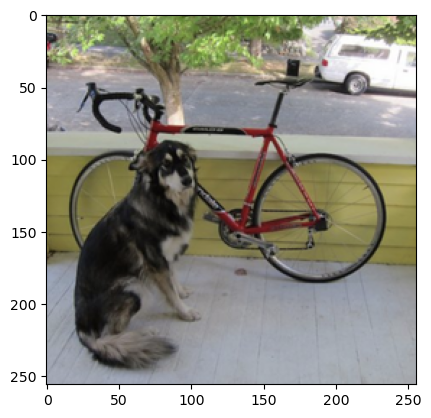

In [13]:
image_path=r"C:\Users\hp\Pictures\dog.png"
image=resize_image(image_path)
plt.imshow(image)

In [14]:
module_handle='https://tfhub.dev/google/faster_rcnn/openimages_v4/inception_resnet_v2/1'
detector=hub.load(module_handle).signatures['default']

URLError: <urlopen error [Errno 11001] getaddrinfo failed>